# Group 2 — Building Age Classification (submission)
**ZAS Data Science Regional Hackathon 2026**

This notebook runs end to end from `data/madrid_train.parquet` and `data/amsterdam_data.parquet` and produces every deliverable:

| Deliverable | Where |
|---|---|
| 1. Stage-1 model (Madrid) | `group2_outputs/stage1_madrid.joblib` (+ `stage1_transfer_base.joblib`) |
| 2. Adaptation code, parameterised by `n`, fixed seeds | `build_stage2(n, seed)` and `predict_amsterdam(new_df, n)` below; five Stage-2 models saved as `stage2_amsterdam_n{n}.joblib` |
| **Baseline vs best model** (Madrid and Amsterdam, same folds and draws) | Sections 4 and 7 |
| Madrid CV (mean ± std, confusion proportions) | Section 5 |
| Amsterdam CV for n = 5, 25, 50, 100, 200 | Section 7 → `group2_outputs/required_results.csv`, `baseline_vs_best.csv`, `f1_vs_log2_n.png` |
| Predictions for hidden test pixels | Section 8: `predict_madrid(new_df)`, `predict_amsterdam(new_df, n)` |

**Method in one line:** clean the photos (broken scenes removed, warm-season median per year) → 321 label-free features describing *change over time* → per-city standardisation → Madrid: LightGBM + XGBoost + Random Forest ensemble → Amsterdam: CatBoost base adapted by recalibration, weighted fine-tuning and self-training, ensembled, class-mix-corrected when n ≥ 25, spatially smoothed.

Runtime: ≈ 40 min on 8 CPU threads (≈ 15 min with an NVIDIA GPU). Seeds: 42 for models, 0–9 for the Amsterdam draws.

## 1 · Setup

In [1]:
import importlib, subprocess, sys
for pkg in ['lightgbm', 'xgboost', 'catboost', 'pyarrow']:          # install anything the platform is missing
    try: importlib.import_module(pkg)
    except ImportError: subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', pkg], check=False)

import os, gc, json, time, warnings, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import uniform_filter
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix
import lightgbm as lgb, xgboost as xgb, catboost as cb
warnings.filterwarnings('ignore')

DATA_DIR = next(Path(p) for p in ['data', '../data', '.'] if (Path(p) / 'madrid_train.parquet').exists())
OUT = Path('group2_outputs'); OUT.mkdir(exist_ok=True)
SEED, N_JOBS = 42, os.cpu_count()
CITIES = ['Madrid', 'Amsterdam']; FILES = {'Madrid': 'madrid_train.parquet', 'Amsterdam': 'amsterdam_data.parquet'}
BANDS = ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']; PID = ['px_key', 'py_key']
YEARS = np.arange(1984, 2026); EARLY, LATE = YEARS <= 2003, YEARS >= 2004
CLASSES = np.array([1, 2, 3, 4]); CLASS_EVENTS = {'Madrid': 1960, 'Amsterdam': 1945}
N_SHOTS, N_DRAWS = [5, 25, 50, 100, 200], 10
SMOKE = os.environ.get('SMOKE') == '1'          # quick self-test only (15 % of pixels, 1 draw); off by default
if SMOKE: N_DRAWS = 1
def mf1(a, b): return f1_score(a, b, average='macro')
def log(m): print(f"[{time.strftime('%H:%M:%S')}] {m}", flush=True)

def _gpu():
    try: return subprocess.run(['nvidia-smi', '-L'], capture_output=True, text=True, timeout=20).stdout.strip()
    except Exception: return ''
XGB_DEVICE, CAT_TASK = 'cpu', 'CPU'
if _gpu():
    try: xgb.XGBClassifier(n_estimators=2, device='cuda').fit(np.random.rand(50, 3), np.random.randint(0, 2, 50)); XGB_DEVICE = 'cuda'
    except Exception: pass
    try: cb.CatBoostClassifier(iterations=2, task_type='GPU', verbose=0).fit(np.random.rand(50, 3), np.random.randint(0, 2, 50)); CAT_TASK = 'GPU'
    except Exception: pass
log(f"data: {DATA_DIR.resolve()} | {N_JOBS} CPU threads | XGBoost {XGB_DEVICE} | CatBoost {CAT_TASK}")

[11:58:08] data: data | 24 CPU threads | XGBoost cuda | CatBoost GPU


## 2 · Cleaning and yearly composite
Each raw row holds up to 3 photos of one pixel-year. We drop photos that are not clear, come from one of the **3 broken scenes**, are saturated, contain zeros, are cirrus-contaminated or have Blue > 15 000; then keep **one value per pixel-year = median of clean May–September photos** (other months only as fallback). This cuts year-to-year noise by 40–46 % versus the starter's "first clean photo".

In [2]:
CUM = np.array([31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334])
def to_long(df):
    parts = []
    for s in (1, 2, 3):
        ren = {f'{b}_{s}': b for b in BANDS}
        ren.update({f'QA_PIXEL_{s}': 'QA_PIXEL', f'QA_RADSAT_{s}': 'QA_RADSAT', f'doy_{s}': 'doy', f'scene_id_{s}': 'scene_id', f'qa_valid_{s}': 'qa_valid'})
        parts.append(df[PID + ['year'] + list(ren)].rename(columns=ren))
    o = pd.concat(parts, ignore_index=True); o[BANDS] = o[BANDS].astype('float32')
    o['month'] = np.searchsorted(CUM, o.doy.to_numpy(), side='left') + 1
    o['cirrus'] = (o.QA_PIXEL.to_numpy().astype(np.int64) >> 14) & 3
    return o

def find_bad_scenes(o):
    v = o[o.qa_valid.astype(bool)]
    t = v.groupby('scene_id', observed=True).Blue.agg(med='median', frac=lambda x: (x > 15000).mean())
    return set(t.index[(t.med > 12000) | (t.frac > .05)])

def clean_and_composite(raw, bad_scenes):
    o = to_long(raw)
    bad = (~o.qa_valid.astype(bool)) | o.scene_id.isin(bad_scenes) | (o.QA_RADSAT > 0) | (o[BANDS] == 0).any(axis=1) | (o.cirrus == 3) | (o.Blue > 15000)
    o = o[~bad.values]
    keys = PID + ['year']; warm = o.month.between(5, 9)
    allm = o.groupby(keys)[BANDS].median(); warmm = o[warm].groupby(keys)[BANDS].median().reindex(allm.index)
    use = warmm.notna().all(axis=1); comp = warmm.where(use, allm)
    comp['n_photos'] = o.groupby(keys).size(); comp['fallback'] = (~use).astype(float)
    return comp.reset_index()

def pixel_table(raw, city=None):
    agg = {'coverage': ('coverage', 'first')}
    if 'weighted_mean_year' in raw: agg['wmy'] = ('weighted_mean_year', 'first')
    p = raw.groupby(PID).agg(**agg).reset_index().sort_values(PID).reset_index(drop=True)
    if city and 'wmy' in p:
        p['age_class'] = pd.cut(p.wmy, [-np.inf, CLASS_EVENTS[city], 1984, 2004, np.inf], labels=[1, 2, 3, 4]).astype(int)
    return p

RAW, YEARLY, PIX, BAD = {}, {}, {}, set()
for c in CITIES:
    RAW[c] = pd.read_parquet(DATA_DIR / FILES[c])
    if SMOKE: RAW[c] = RAW[c].merge(RAW[c][PID].drop_duplicates().sample(frac=.15, random_state=SEED), on=PID)
    BAD |= find_bad_scenes(to_long(RAW[c]))
def starter_flat(raw):                    # the organisers' starter view: first clear photo per year, Blue <= 15 000
    out = raw[PID + ['year']].copy()
    for b in BANDS:
        col = np.full(len(raw), np.nan)
        for s in (1, 2, 3):
            col = np.where(np.isnan(col) & raw[f'qa_valid_{s}'].fillna(False).to_numpy(bool), raw[f'{b}_{s}'].to_numpy(), col)
        out[b] = col
    out = out.dropna(subset=BANDS)
    return out[out.Blue <= 15000]
STARTER_FLAT = {}
for c in CITIES:
    PIX[c] = pixel_table(RAW[c], c)
    YEARLY[c] = clean_and_composite(RAW[c], BAD)
    STARTER_FLAT[c] = starter_flat(RAW[c])
    log(f"{c}: {len(PIX[c]):,} pixels, {len(YEARLY[c]):,} clean pixel-years")
log(f"broken scenes removed: {sorted(BAD)}")
del RAW; gc.collect()

[11:58:18] Madrid: 76,263 pixels, 3,147,969 clean pixel-years


[11:58:20] Amsterdam: 25,992 pixels, 1,058,169 clean pixel-years


[11:58:20] broken scenes removed: ['LE07_L2SP_198023_20020417_20200916_02_T2', 'LT05_L2SP_199023_19961109_20211124_02_T1', 'LT05_L2SP_201032_19951207_20211123_02_T2']


0

## 3 · Feature engineering (321 label-free features)
| Group | Content |
|---|---|
| S (58) | means/stds of bands and 5 indices, early (≤2003) vs late (≥2004) statistics, year-on-year change |
| A (20) | NBR, NDTI, tasselled-cap brightness/greenness/wetness |
| B (88) | robust median, IQR, percentiles, slopes, volatility |
| C (35) | medians of 6-year windows |
| D (36) | **one-break change-point**: year, size, strength of the main jump; biggest single-year jump |
| E (23) | relative: late − early, ratios, band shape |
| F (5) | coverage, missing years, photos per year |
| H (22) | **two-break change-point** and steepest vegetation→built transition |
| G (34) | spatial context: leave-self-out neighbourhood means at 90/210/450 m, building density |

All computed **without labels**, identically for both cities and for any new pixels.

In [3]:
TC = {'TCB': [0.3029, 0.2786, 0.4733, 0.5599, 0.5080, 0.1872], 'TCG': [-0.2941, -0.2430, -0.5424, 0.7276, 0.0713, -0.1608],
      'TCW': [0.1511, 0.1973, 0.3283, 0.3407, -0.7117, -0.4559]}
IDX5 = ['NDVI', 'NDBI', 'UI', 'MNDWI', 'BSI']; IDXN = ['NBR', 'NDTI', 'TCB', 'TCG', 'TCW']
K = ['NDVI', 'NDBI', 'MNDWI', 'BSI', 'NBR', 'NDTI', 'TCB', 'TCG', 'TCW', 'SWIR1', 'NIR']
nmean = lambda M: np.nanmean(M, 1); nstd = lambda M: np.nanstd(M, 1, ddof=1); nmed = lambda M: np.nanmedian(M, 1)

def make_cube(yr, pix):
    wide = yr.set_index(PID + ['year'])[BANDS].unstack('year').reindex(pd.MultiIndex.from_frame(pix[PID]))
    R = {b: wide[b].reindex(columns=YEARS).to_numpy(np.float32) for b in BANDS}
    B, G, Rd, N, S1, S2 = (R[b] for b in BANDS); e = 1e-6
    R.update({'NDVI': (N - Rd) / (N + Rd + e), 'NDBI': (S1 - N) / (S1 + N + e), 'UI': (S2 - N) / (S2 + N + e), 'MNDWI': (G - S1) / (G + S1 + e),
              'BSI': ((S1 + Rd) - (N + B)) / ((S1 + Rd) + (N + B) + e), 'NBR': (N - S2) / (N + S2 + e), 'NDTI': (S1 - S2) / (S1 + S2 + e)})
    refl = [R[b] * 2.75e-5 - 0.2 for b in BANDS]
    for k, w in TC.items(): R[k] = sum(wi * r for wi, r in zip(w, refl)).astype(np.float32)
    F = {k: pd.DataFrame(v.T).interpolate(limit_direction='both').to_numpy(np.float32).T for k, v in R.items()}
    return R, F, ~np.isnan(R['Blue'])

def slope(M, yrs):
    x = np.where(np.isnan(M), np.nan, yrs[None, :].astype(np.float32)); xm, ym = np.nanmean(x, 1, keepdims=True), np.nanmean(M, 1, keepdims=True)
    num, den = np.nansum((x - xm) * (M - ym), 1), np.nansum((x - xm) ** 2, 1)
    return np.where(den > 0, num / np.where(den > 0, den, 1), np.nan)

def step_break(Y):
    T = Y.shape[1]; k = np.arange(1, T); cs = np.cumsum(Y, 1, dtype=np.float64)[:, :-1]; tot = Y.sum(1, keepdims=True, dtype=np.float64)
    bef, aft = cs / k, (tot - cs) / (T - k); gain = k * (T - k) / T * (aft - bef) ** 2; b = gain.argmax(1); i = np.arange(len(Y))
    return YEARS[b + 1], (aft - bef)[i, b], gain[i, b] / (Y.var(1, dtype=np.float64) * T + 1e-12)

def two_break(Y):
    Y = Y.astype(np.float64); n, T = Y.shape; cs = np.concatenate([np.zeros((n, 1)), np.cumsum(Y, 1)], 1)
    tss = ((Y - Y.mean(1, keepdims=True)) ** 2).sum(1) + 1e-12; base = cs[:, T] ** 2 / T
    best = np.full(n, -np.inf); bi = np.zeros(n, int); bj = np.zeros(n, int)
    for i in range(2, T - 1):
        js = np.arange(i + 2, T - 1)
        if not len(js): continue
        g = cs[:, [i]] ** 2 / i + (cs[:, js] - cs[:, [i]]) ** 2 / (js - i) + (cs[:, [T]] - cs[:, js]) ** 2 / (T - js) - base[:, None]
        k = g.argmax(1); gv = g[np.arange(n), k]; u = gv > best; best[u] = gv[u]; bi[u] = i; bj[u] = js[k[u]]
    r = np.arange(n); l1, l2, l3 = cs[r, bi] / bi, (cs[r, bj] - cs[r, bi]) / (bj - bi), (cs[r, T] - cs[r, bj]) / (T - bj)
    return YEARS[bi], YEARS[bj], l2 - l1, l3 - l2, best / tss

def base_features(yr, pix):
    R, F, m = make_cube(yr, pix); o = {}
    for ch in BANDS + IDX5: o[f'{ch}_mean'] = nmean(R[ch]); o[f'{ch}_std'] = nstd(R[ch])                       # S
    for b in BANDS:
        o[f'{b}_early_mean'] = nmean(R[b][:, EARLY]); o[f'{b}_early_std'] = nstd(R[b][:, EARLY])
        o[f'{b}_late_mean'] = nmean(R[b][:, LATE]); o[f'{b}_late_std'] = nstd(R[b][:, LATE])
        d = np.diff(F[b], axis=1); o[f'd_{b}_mean'] = d.mean(1); o[f'd_{b}_std'] = d.std(1, ddof=1)
    for ch in IDXN:                                                                                               # A
        o[f'{ch}_mean'] = nmean(R[ch]); o[f'{ch}_std'] = nstd(R[ch]); o[f'{ch}_early_mean'] = nmean(R[ch][:, EARLY]); o[f'{ch}_late_mean'] = nmean(R[ch][:, LATE])
    for ch in K:                                                                                                  # B
        q = {p: np.nanpercentile(R[ch], p, axis=1) for p in (10, 25, 50, 75, 90)}
        o[f'{ch}_med'] = q[50]; o[f'{ch}_iqr'] = q[75] - q[25]; o[f'{ch}_p10'] = q[10]; o[f'{ch}_p90'] = q[90]
        o[f'{ch}_slope'] = slope(R[ch], YEARS); o[f'{ch}_slope_early'] = slope(R[ch][:, EARLY], YEARS[EARLY]); o[f'{ch}_slope_late'] = slope(R[ch][:, LATE], YEARS[LATE])
        o[f'{ch}_volatility'] = nmed(np.abs(np.diff(R[ch], axis=1)))
    for ch in ['NDVI', 'NDBI', 'BSI', 'TCB', 'SWIR1']:                                                            # C
        for a in range(1984, 2026, 6): o[f'{ch}_w{a}'] = nmed(R[ch][:, (YEARS >= a) & (YEARS <= a + 5)])
    S_, Y_ = [], []                                                                                               # D
    for ch in ['NDVI', 'NDBI', 'BSI', 'SWIR1', 'TCB', 'TCW', 'NBR']:
        y_, s_, st = step_break(F[ch]); o[f'{ch}_brk_year'] = y_; o[f'{ch}_brk_size'] = s_; o[f'{ch}_brk_strength'] = st
        o[f'{ch}_brk_after2004'] = (y_ >= 2004) * st; S_.append(st); Y_.append(y_)
    S_, Y_ = np.vstack(S_), np.vstack(Y_); o['brk_year_best'] = Y_[S_.argmax(0), np.arange(S_.shape[1])]; o['brk_strength_max'] = S_.max(0)
    for ch in ['NDVI', 'NDBI', 'SWIR1']:
        d = np.diff(F[ch], axis=1); j = np.abs(d).argmax(1); o[f'{ch}_jump_year'] = YEARS[j + 1]; o[f'{ch}_jump_size'] = d[np.arange(len(d)), j]
    for ch in K: o[f'{ch}_late_minus_early'] = nmed(R[ch][:, LATE]) - nmed(R[ch][:, EARLY])                      # E
    meds = {b: nmed(R[b]) for b in BANDS}; tot = sum(meds.values())
    for b in BANDS: o[f'{b}_late_over_early'] = nmed(R[b][:, LATE]) / nmed(R[b][:, EARLY]); o[f'{b}_shape'] = meds[b] / tot
    yr2 = yr.groupby(PID).agg(ppy=('n_photos', 'mean'), fb=('fallback', 'mean')).reindex(pd.MultiIndex.from_frame(pix[PID]))
    run = np.zeros(len(m)); best = np.zeros(len(m))
    for t in range(m.shape[1]): run = (run + 1) * (~m[:, t]); best = np.maximum(best, run)
    o.update({'coverage': pix.coverage.values, 'frac_filled': 1 - m.mean(1), 'longest_gap': best,                # F
              'photos_per_year': yr2.ppy.values, 'frac_fallback': yr2.fb.values})
    for ch in ['NDVI', 'NDBI', 'TCB']:                                                                            # H
        y1, y2, d1, d2, st = two_break(F[ch]); _, _, st1 = step_break(F[ch])
        o.update({f'{ch}_brk2_y1': y1, f'{ch}_brk2_y2': y2, f'{ch}_brk2_d1': d1, f'{ch}_brk2_d2': d2, f'{ch}_brk2_strength': st, f'{ch}_brk2_extra': st - st1})
    for ch, sg in [('NDVI', -1), ('NDBI', 1)]:
        ma = pd.DataFrame(F[ch].T).rolling(3, center=True, min_periods=1).mean().to_numpy().T; d = sg * np.diff(ma, axis=1); j = d.argmax(1)
        o[f'{ch}_steep_year'] = YEARS[j + 1]; o[f'{ch}_steep_size'] = d[np.arange(len(d)), j]
    return pd.DataFrame(o)

def neigh(pix, v, size, stat='mean'):
    x = (pix.px_key - pix.px_key.min()).to_numpy(); y_ = (pix.py_key - pix.py_key.min()).to_numpy(); H, W = y_.max() + 1, x.max() + 1; ok = ~np.isnan(v)
    V, M, V2 = np.zeros((H, W)), np.zeros((H, W)), np.zeros((H, W)); V[y_[ok], x[ok]] = v[ok]; M[y_[ok], x[ok]] = 1; V2[y_[ok], x[ok]] = v[ok] ** 2
    n = size ** 2; s = uniform_filter(V, size, mode='constant') * n - V; s2 = uniform_filter(V2, size, mode='constant') * n - V2
    c = (uniform_filter(M, size, mode='constant') * n - M)[y_, x]; mean = np.where(c > .5, s[y_, x] / np.maximum(c, 1), np.nan)
    if stat == 'mean': return mean
    return np.sqrt(np.clip(np.where(c > 1.5, s2[y_, x] / np.maximum(c, 1) - mean ** 2, np.nan), 0, None))

GKEYS = ['NDVI_med', 'NDBI_med', 'TCB_med', 'SWIR1_med', 'NDVI_late_minus_early', 'NDVI_brk_strength', 'NDVI_brk_year', 'NDBI_brk_size', 'coverage']
def spatial_features(pix, base):
    o = {}; x = (pix.px_key - pix.px_key.min()).to_numpy(); y_ = (pix.py_key - pix.py_key.min()).to_numpy()
    Mk = np.zeros((y_.max() + 1, x.max() + 1)); Mk[y_, x] = 1
    for f in GKEYS:
        for s in (3, 7, 15): o[f'nb{s}_{f}'] = neigh(pix, base[f].to_numpy(np.float64), s)
    for s in (3, 7, 15): o[f'density{s}'] = (uniform_filter(Mk, s, mode='constant') * s ** 2 - 1)[y_, x] / (s ** 2 - 1)
    for f in ['NDVI_med', 'NDVI_brk_year']: o[f'nbstd7_{f}'] = neigh(pix, base[f].to_numpy(np.float64), 7, 'std')
    for f in ['NDVI_med', 'TCB_med']: o[f'diff7_{f}'] = base[f].to_numpy() - o[f'nb7_{f}']
    return pd.DataFrame(o)

BASE, FEATS = {}, {}
for c in CITIES:
    t = time.time(); BASE[c] = base_features(YEARLY[c], PIX[c])
    FEATS[c] = pd.concat([BASE[c], spatial_features(PIX[c], BASE[c])], axis=1)
    log(f"{c}: {FEATS[c].shape[1]} features ({time.time()-t:.0f}s)")
y = {c: PIX[c].age_class.to_numpy() for c in CITIES}; ym, ya = y['Madrid'], y['Amsterdam']

[12:00:02] Madrid: 321 features (102s)


[12:00:39] Amsterdam: 321 features (37s)


### Per-city standardisation and the two feature sets
Each feature is converted to a z-score **within its own city** (no labels used) — the largest label-free transfer gain we found (Amsterdam zero-shot 0.413 → 0.520). The **RICH** set (top-120 features by LightGBM gain) is used for Madrid; the **TRANSFER** set (one- and two-break change-points, starter-like statistics, robust index statistics — no spatial features, which do not transfer) is used for everything that crosses cities.

In [4]:
def fit_scaler(X): mu = np.nanmean(X, 0); sd = np.nanstd(X, 0); sd[~(sd > 0)] = 1; return mu, sd
def apply_scaler(X, st): return ((X - st[0]) / st[1]).astype(np.float32)
ALL = list(FEATS['Madrid'].columns)
cw = len(ym) / (4 * np.bincount(ym, minlength=5)[1:]); W_MAD = PIX['Madrid'].coverage.to_numpy() * cw[ym - 1]; W_MAD /= W_MAD.mean()
LGB = dict(n_estimators=400, learning_rate=0.05, num_leaves=63, colsample_bytree=0.5, subsample=0.8, subsample_freq=1, min_child_samples=20,
           n_jobs=N_JOBS, random_state=SEED, verbose=-1)
sel = lgb.LGBMClassifier(**LGB, importance_type='gain').fit(apply_scaler(FEATS['Madrid'][ALL].to_numpy(np.float64), fit_scaler(FEATS['Madrid'][ALL].to_numpy(np.float64))), ym, sample_weight=W_MAD)
RICH = list(pd.Series(sel.feature_importances_, index=ALL).sort_values(ascending=False).index[:120])
G_S = [f'{ch}_{s}' for ch in BANDS + IDX5 for s in ('mean', 'std')] + \
      [f'{p}{b}_{s}' for b in BANDS for p, s in [('', 'early_mean'), ('', 'early_std'), ('', 'late_mean'), ('', 'late_std'), ('d_', 'mean'), ('d_', 'std')]]
G_D = [f'{ch}_brk_{s}' for ch in ['NDVI', 'NDBI', 'BSI', 'SWIR1', 'TCB', 'TCW', 'NBR'] for s in ('year', 'size', 'strength', 'after2004')] + \
      ['brk_year_best', 'brk_strength_max'] + [f'{ch}_jump_{s}' for ch in ['NDVI', 'NDBI', 'SWIR1'] for s in ('year', 'size')]
G_H = [f'{ch}_brk2_{s}' for ch in ['NDVI', 'NDBI', 'TCB'] for s in ('y1', 'y2', 'd1', 'd2', 'strength', 'extra')] + \
      [f'{ch}_steep_{s}' for ch in ['NDVI', 'NDBI'] for s in ('year', 'size')]
TRANSFER = G_S + G_D + G_H + [f'{ch}_{s}' for ch in ['NDVI', 'NDBI', 'MNDWI', 'BSI', 'NBR', 'NDTI', 'TCG', 'TCW'] for s in ['med', 'iqr', 'slope']]
assert len(TRANSFER) == 140 and set(TRANSFER) <= set(ALL)
SCALER = {(c, k): fit_scaler(FEATS[c][cols].to_numpy(np.float64)) for c in CITIES for k, cols in [('RICH', RICH), ('TRANSFER', TRANSFER)]}
X = {(c, k): apply_scaler(FEATS[c][cols].to_numpy(np.float64), SCALER[(c, k)]) for c in CITIES for k, cols in [('RICH', RICH), ('TRANSFER', TRANSFER)]}
log(f"RICH = {len(RICH)} features, TRANSFER = {len(TRANSFER)} features")

[12:00:50] RICH = 120 features, TRANSFER = 140 features


## 4 · Baseline model — the organisers' starter approach
Reproduced exactly as in the starter notebooks, so that every improvement is measured against it **on the same validation folds and the same Amsterdam draws**:
- data: first clear photo of each year (Blue ≤ 15 000), gaps filled by interpolation;
- features: the starter's 60 features (overall / early / late means and stds, year-on-year change, 5 indices, 2 coverage flags);
- scaling: fitted on Madrid, applied to Amsterdam;
- Madrid model: **Random Forest** (500 trees, balanced class weights);
- Amsterdam transfer: **prototype** (nearest class mean of the n labelled pixels).

In [5]:
def starter_features(flat, pix):
    R, F, m = make_cube(flat, pix); o = {}
    for ch in BANDS + IDX5: o[f'{ch}_mean'] = F[ch].mean(1); o[f'{ch}_std'] = F[ch].std(1, ddof=1)
    for b in BANDS:
        o[f'{b}_early_mean'] = F[b][:, EARLY].mean(1); o[f'{b}_early_std'] = F[b][:, EARLY].std(1, ddof=1)
        o[f'{b}_late_mean'] = F[b][:, LATE].mean(1); o[f'{b}_late_std'] = F[b][:, LATE].std(1, ddof=1)
        d = np.diff(F[b], axis=1); o[f'd_{b}_mean'] = d.mean(1); o[f'd_{b}_std'] = d.std(1, ddof=1)
    o['has_early_data'] = m[:, EARLY].any(1).astype(float); o['has_late_data'] = m[:, LATE].any(1).astype(float)
    return pd.DataFrame(o)
SF = {c: starter_features(STARTER_FLAT[c], PIX[c]).to_numpy(np.float64) for c in CITIES}
del STARTER_FLAT; gc.collect()
sc_m = fit_scaler(SF['Madrid']); XS = {c: np.nan_to_num(apply_scaler(SF[c], sc_m)) for c in CITIES}      # starter: Madrid scaling for both cities
BLOCKS = (PIX['Madrid'].px_key // 67).astype(str) + '_' + (PIX['Madrid'].py_key // 67).astype(str)
SPATIAL_FOLDS = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(np.zeros(len(ym)), ym, BLOCKS))
RANDOM_FOLDS = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(np.zeros(len(ym)), ym))
def rf_baseline(): return RandomForestClassifier(n_estimators=500, class_weight='balanced', random_state=SEED, n_jobs=N_JOBS)
def cv_baseline(folds):
    return np.array([mf1(ym[te], rf_baseline().fit(XS['Madrid'][tr], ym[tr]).predict(XS['Madrid'][te])) for tr, te in folds])
base_spatial, base_random = cv_baseline(SPATIAL_FOLDS), cv_baseline(RANDOM_FOLDS)
BASELINE_RF = rf_baseline().fit(XS['Madrid'], ym)
base_zero = mf1(ya, BASELINE_RF.predict(XS['Amsterdam']))
log(f"BASELINE  Madrid spatial CV {base_spatial.mean():.3f} ± {base_spatial.std():.3f} | random CV {base_random.mean():.3f} ± {base_random.std():.3f} | Amsterdam zero-shot {base_zero:.3f}")

[12:02:56] BASELINE  Madrid spatial CV 0.574 ± 0.030 | random CV 0.618 ± 0.005 | Amsterdam zero-shot 0.334


## 5 · Best model — Stage 1, Madrid
Ensemble (average of class probabilities) of **LightGBM, XGBoost and Random Forest** on the RICH set, trained with weights = coverage × balanced class weight. Validated with **spatial-block 5-fold CV** (whole 2 km × 2 km blocks held out, so near-identical neighbours cannot leak). Random 5-fold CV is shown for comparison.

*Model selection (from our full notebook, spatial CV): Ensemble 0.652 · LightGBM 0.649 · XGBoost 0.646 · Random Forest 0.634 · CatBoost 0.631 · MLP 0.628 · Logistic Regression 0.603.*

In [6]:
def make(name):
    if name == 'LightGBM': return lgb.LGBMClassifier(**LGB)
    if name == 'XGBoost':  return xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.8, colsample_bytree=0.5, tree_method='hist',
                                                    device=XGB_DEVICE, n_jobs=N_JOBS, random_state=SEED, eval_metric='mlogloss')
    if name == 'RandomForest': return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, max_features='sqrt', n_jobs=N_JOBS, random_state=SEED)
    if name == 'CatBoost': return cb.CatBoostClassifier(iterations=400, depth=6, learning_rate=0.08, thread_count=N_JOBS, random_seed=SEED, verbose=0, task_type=CAT_TASK)

class Ensemble:
    MEMBERS = ['LightGBM', 'XGBoost', 'RandomForest']
    def fit(self, Xm, yv, w):
        self.models = []
        for n in self.MEMBERS:
            m = make(n); Xi = np.nan_to_num(Xm) if n == 'RandomForest' else Xm
            m.fit(Xi, yv - 1 if n == 'XGBoost' else yv, sample_weight=w); self.models.append((n, m))
        return self
    def predict_proba(self, Xm):
        return np.mean([m.predict_proba(np.nan_to_num(Xm) if n == 'RandomForest' else Xm) for n, m in self.models], axis=0)

XR = X[('Madrid', 'RICH')]
def run_cv(splits, label):
    P = np.zeros((len(ym), 4)); sc = []
    for f, (tr, te) in enumerate(splits):
        P[te] = Ensemble().fit(XR[tr], ym[tr], W_MAD[tr]).predict_proba(XR[te]); sc.append(mf1(ym[te], CLASSES[P[te].argmax(1)]))
        log(f"  {label} fold {f+1}/5: {sc[-1]:.3f}")
    return np.array(sc), P
spatial_scores, OOF = run_cv(SPATIAL_FOLDS, 'spatial')
random_scores, _ = run_cv(RANDOM_FOLDS, 'random')
log(f"Madrid spatial-block CV macro F1 = {spatial_scores.mean():.3f} ± {spatial_scores.std():.3f}   |   random CV = {random_scores.mean():.3f} ± {random_scores.std():.3f}")
cm = confusion_matrix(ym, CLASSES[OOF.argmax(1)], labels=CLASSES); cmp_ = pd.DataFrame(cm / cm.sum(1, keepdims=True), index=[f'true C{k}' for k in CLASSES], columns=[f'pred C{k}' for k in CLASSES])
STAGE1 = Ensemble().fit(XR, ym, W_MAD)                                          # final Madrid model on all pixels
cmp_.round(3)

[12:03:14]   spatial fold 1/5: 0.622


[12:03:34]   spatial fold 2/5: 0.665


[12:03:53]   spatial fold 3/5: 0.621


[12:04:13]   spatial fold 4/5: 0.664


[12:04:31]   spatial fold 5/5: 0.686


...

[12:05:29]   random fold 3/5: 0.741


[12:05:48]   random fold 4/5: 0.734


[12:06:08]   random fold 5/5: 0.735


[12:06:08] Madrid spatial-block CV macro F1 = 0.652 ± 0.026   |   random CV = 0.736 ± 0.003


,pred C1,pred C2,pred C3,pred C4
true C1,0.528,0.380,0.050,0.041
true C2,0.134,0.731,0.087,0.048
true C3,0.045,0.203,0.642,0.110
true C4,0.030,0.118,0.162,0.690


## 6 · Best model — Stage 2, transfer to Amsterdam
**Base model:** CatBoost on the TRANSFER set (best zero-shot of all algorithms: it travels best between cities).
For `n` labelled Amsterdam pixels per class, `build_stage2` creates an Amsterdam model from four ingredients that reuse Madrid's knowledge and Amsterdam's unlabelled pixels:
1. **Recalibration** — logistic regression re-maps the CatBoost log-probabilities using the support set.
2. **Fine-tune** — LightGBM retrained on Madrid + the support pixels (support carries 25 % of total weight).
3. **Self-training** — the 500 most confident unlabelled Amsterdam pixels per class become pseudo-labels for a small LightGBM.
4. **Ensemble → safe class-mix correction → spatial smoothing** — the three are averaged; Amsterdam's class mix is re-estimated by EM **only when n ≥ 25** (with fewer labels it is unreliable; Alexandari et al., ICML 2020); probabilities are blended with neighbours (α and window tuned on Madrid OOF only).

In [7]:
BASE_MODEL = make('CatBoost').fit(X[('Madrid', 'TRANSFER')], ym, sample_weight=W_MAD)
XA, XM = X[('Amsterdam', 'TRANSFER')], X[('Madrid', 'TRANSFER')]
LOGPZ = np.log(BASE_MODEL.predict_proba(XA) + 1e-6)

def smooth(P, pix, alpha, size):
    if alpha >= 1: return P
    N = np.column_stack([neigh(pix, P[:, k].astype(np.float64), size) for k in range(4)]); N = np.where(np.isnan(N), P, N)
    S = alpha * P + (1 - alpha) * N; return S / S.sum(1, keepdims=True)
grid = [(a, s, mf1(ym, CLASSES[smooth(OOF, PIX['Madrid'], a, s).argmax(1)])) for s in (3, 5, 7, 11, 15) for a in (1.0, .7, .5, .3, .15)]
SMOOTH = dict(zip(['alpha', 'size'], max(grid, key=lambda g: g[2])[:2])); log(f"smoothing tuned on Madrid OOF: {SMOOTH}")

def em_prior(P, prior=np.full(4, .25), iters=200, tol=1e-6):
    pi = prior.copy()
    for _ in range(iters):
        Q = P * (pi / prior); Q /= Q.sum(1, keepdims=True); new = Q.mean(0)
        if np.abs(new - pi).max() < tol: break
        pi = new
    return pi

class Stage2:
    def proba(self, Xt, logpz):                   # unsmoothed class probabilities for any Amsterdam pixels
        P = (self.recal.predict_proba(logpz) + self.ft.predict_proba(Xt) + self.st.predict_proba(Xt)) / 3
        if self.prior is not None: P = P * (self.prior / .25); P /= P.sum(1, keepdims=True)
        return P

def sample_support(n, seed):
    rng = np.random.default_rng(seed)
    s = np.concatenate([rng.choice(np.where(ya == k)[0], n, replace=False) for k in CLASSES])
    return s, np.setdiff1d(np.arange(len(ya)), s)

def build_stage2(n, seed):
    s, q = sample_support(n, seed); ys = ya[s]; m = Stage2(); m.n, m.seed, m.support = n, seed, s
    m.recal = LogisticRegression(C=1.0, max_iter=3000).fit(LOGPZ[s], ys)
    w_s = np.full(len(s), .25 * W_MAD.sum() / len(s))
    m.ft = lgb.LGBMClassifier(**dict(LGB, n_estimators=300, random_state=seed)).fit(np.vstack([XM, XA[s]]), np.r_[ym, ys], sample_weight=np.r_[W_MAD, w_s])
    anchor = (m.recal.predict_proba(LOGPZ) + m.ft.predict_proba(XA)) / 2
    pool = np.setdiff1d(np.arange(len(XA)), s); pred = anchor[pool].argmax(1); idx, lab, wt = [s], [ys], [np.full(len(s), 3.0)]
    for k in range(4):
        cand = pool[pred == k]; top = cand[np.argsort(-anchor[cand, k])[:500]]; idx.append(top); lab.append(np.full(len(top), k + 1)); wt.append(anchor[top, k])
    m.st = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=10, colsample_bytree=0.7, n_jobs=N_JOBS,
                              random_state=seed, verbose=-1).fit(XA[np.concatenate(idx)], np.concatenate(lab), sample_weight=np.concatenate(wt))
    m.prior = None
    if n >= 25:                                   # safe class-mix correction
        P = (m.recal.predict_proba(LOGPZ) + m.ft.predict_proba(XA) + m.st.predict_proba(XA)) / 3; m.prior = em_prior(P)
    return m, q

zs = mf1(ya, CLASSES[smooth(np.exp(LOGPZ), PIX['Amsterdam'], **SMOOTH).argmax(1)])
log(f"Amsterdam zero-shot (no labels): {zs:.3f}")

[12:06:35] smoothing tuned on Madrid OOF: {'alpha': 0.5, 'size': 5}


[12:06:36] Amsterdam zero-shot (no labels): 0.624


## 7 · Results — baseline vs best; Amsterdam CV for n = 5, 25, 50, 100, 200
For each n: 10 random support/query splits (seeds 0–9); the Stage-2 model is built from the support set and scored on all other Amsterdam pixels. The **baseline** (starter features + prototype transfer, exactly as in the starter notebook) is scored on the same draws.

[12:07:21] n =   5: 0.654 ± 0.021  (baseline 0.502)


[12:08:09] n =  25: 0.687 ± 0.019  (baseline 0.593)


[12:08:59] n =  50: 0.723 ± 0.004  (baseline 0.607)


[12:09:48] n = 100: 0.740 ± 0.004  (baseline 0.617)


[12:10:38] n = 200: 0.757 ± 0.002  (baseline 0.615)


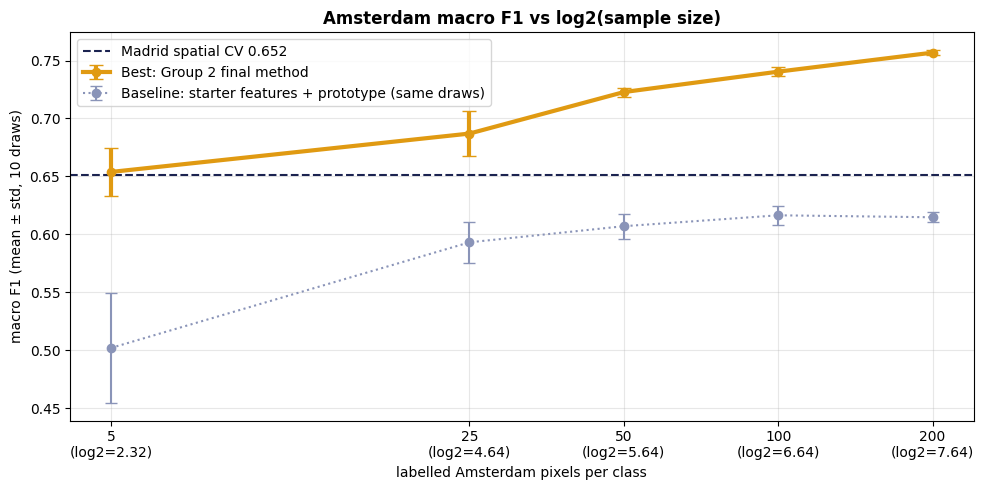

,setting,Baseline (starter: RF + prototype),Best (Group 2)
0,Madrid — spatial-block 5-fold CV,0.574 ± 0.030,0.652 ± 0.026
1,Madrid — random 5-fold CV,0.618 ± 0.005,0.736 ± 0.003
2,Amsterdam — zero-shot (no labels),0.334,0.624
3,Amsterdam — n = 5 per class,0.502 ± 0.047,0.654 ± 0.021
4,Amsterdam — n = 25 per class,0.593 ± 0.018,0.687 ± 0.019
5,Amsterdam — n = 50 per class,0.607 ± 0.011,0.723 ± 0.004
6,Amsterdam — n = 100 per class,0.617 ± 0.008,0.740 ± 0.004
7,Amsterdam — n = 200 per class,0.615 ± 0.004,0.757 ± 0.002
8,Amsterdam — average of the 5 n,0.587,0.712


,city,setting,labelled pixels,macro F1 mean,macro F1 std
0,Madrid,spatial-block 5-fold CV,all,0.6516,0.0255
1,Madrid,random 5-fold CV,all,0.7364,0.0026
2,Amsterdam,zero-shot,0,0.6235,NaN
3,Amsterdam,n = 5 per class (10 draws),20,0.6539,0.0210
4,Amsterdam,n = 25 per class (10 draws),100,0.6870,0.0193
5,Amsterdam,n = 50 per class (10 draws),200,0.7228,0.0039
6,Amsterdam,n = 100 per class (10 draws),400,0.7404,0.0040
7,Amsterdam,n = 200 per class (10 draws),800,0.7568,0.0023


In [8]:
def prototype(s):                                # baseline transfer: starter features, nearest class mean
    X0 = XS['Amsterdam']; P_ = np.stack([X0[s][ya[s] == k].mean(0) for k in CLASSES])
    return CLASSES[((X0 ** 2).sum(1)[:, None] - 2 * X0 @ P_.T + (P_ ** 2).sum(1)[None]).argmin(1)]
rows = []
for n in N_SHOTS:
    for d in range(N_DRAWS):
        m, q = build_stage2(n, d)
        P = smooth(m.proba(XA, LOGPZ), PIX['Amsterdam'], **SMOOTH)
        rows.append({'n': n, 'draw': d, 'Group 2': mf1(ya[q], CLASSES[P[q].argmax(1)]), 'Baseline': mf1(ya[q], prototype(m.support)[q])})
    r = pd.DataFrame(rows).query('n == @n'); log(f"n = {n:3d}: {r['Group 2'].mean():.3f} ± {r['Group 2'].std(ddof=0):.3f}  (baseline {r['Baseline'].mean():.3f})")
res = pd.DataFrame(rows); res.to_csv(OUT / 'amsterdam_all_draws.csv', index=False)
agg = res.groupby('n')[['Group 2', 'Baseline']].agg(['mean', lambda x: x.std(ddof=0)]).round(4)
agg.columns = ['Group 2 mean', 'Group 2 std', 'baseline mean', 'baseline std']

required = pd.DataFrame(
    [['Madrid', 'spatial-block 5-fold CV', 'all', spatial_scores.mean(), spatial_scores.std()], ['Madrid', 'random 5-fold CV', 'all', random_scores.mean(), random_scores.std()],
     ['Amsterdam', 'zero-shot', 0, zs, np.nan]] +
    [['Amsterdam', f'n = {n} per class (10 draws)', 4 * n, agg.loc[n, 'Group 2 mean'], agg.loc[n, 'Group 2 std']] for n in N_SHOTS],
    columns=['city', 'setting', 'labelled pixels', 'macro F1 mean', 'macro F1 std']).round(4)
required.to_csv(OUT / 'required_results.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 5)); lx = np.log2(N_SHOTS)
ax.errorbar(lx, agg['Group 2 mean'], yerr=agg['Group 2 std'], marker='o', lw=3, capsize=5, color='#E09A12', label='Best: Group 2 final method')
ax.errorbar(lx, agg['baseline mean'], yerr=agg['baseline std'], marker='o', ls=':', capsize=4, color='#8A94B8', label='Baseline: starter features + prototype (same draws)')
ax.axhline(spatial_scores.mean(), ls='--', color='#1B2350', label=f'Madrid spatial CV {spatial_scores.mean():.3f}')
ax.set_xticks(lx); ax.set_xticklabels([f'{n}\n(log2={l:.2f})' for n, l in zip(N_SHOTS, lx)]); ax.set_xlabel('labelled Amsterdam pixels per class')
ax.set_ylabel('macro F1 (mean ± std, 10 draws)'); ax.set_title('Amsterdam macro F1 vs log2(sample size)', fontweight='bold'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'f1_vs_log2_n.png', dpi=150); plt.show()

fmt = lambda m, s: f"{m:.3f} ± {s:.3f}"
comparison = pd.DataFrame(
    [['Madrid — spatial-block 5-fold CV', fmt(base_spatial.mean(), base_spatial.std()), fmt(spatial_scores.mean(), spatial_scores.std())],
     ['Madrid — random 5-fold CV', fmt(base_random.mean(), base_random.std()), fmt(random_scores.mean(), random_scores.std())],
     ['Amsterdam — zero-shot (no labels)', f"{base_zero:.3f}", f"{zs:.3f}"]] +
    [[f'Amsterdam — n = {n} per class', fmt(agg.loc[n, 'baseline mean'], agg.loc[n, 'baseline std']), fmt(agg.loc[n, 'Group 2 mean'], agg.loc[n, 'Group 2 std'])] for n in N_SHOTS] +
    [['Amsterdam — average of the 5 n', f"{agg['baseline mean'].mean():.3f}", f"{agg['Group 2 mean'].mean():.3f}"]],
    columns=['setting', 'Baseline (starter: RF + prototype)', 'Best (Group 2)'])
comparison.to_csv(OUT / 'baseline_vs_best.csv', index=False)
display(comparison)
required

## 8 · Saved models and predictions for hidden test pixels
`predict_madrid(new_df)` and `predict_amsterdam(new_df, n)` take **raw rows in the same format as the provided parquet files** (labels not needed) and return one age class per pixel. Features are computed exactly as above; neighbourhood information uses the provided pixels plus the new ones; scaling uses the statistics of the provided city data. The five Stage-2 models (one per n, support draw seed 0) are saved.

In [9]:
STAGE2 = {n: build_stage2(n, 0)[0] for n in N_SHOTS}
joblib.dump({'model': STAGE1, 'features': RICH, 'scaler': SCALER[('Madrid', 'RICH')]}, OUT / 'stage1_madrid.joblib', compress=3)
joblib.dump({'model': BASE_MODEL, 'features': TRANSFER, 'scaler_madrid': SCALER[('Madrid', 'TRANSFER')]}, OUT / 'stage1_transfer_base.joblib', compress=3)
for n, m in STAGE2.items(): joblib.dump(m, OUT / f'stage2_amsterdam_n{n}.joblib', compress=3)
json.dump({'RICH': RICH, 'TRANSFER': TRANSFER, 'SMOOTH': SMOOTH, 'broken_scenes': sorted(BAD)}, open(OUT / 'config.json', 'w'), indent=1)

def _features_with_context(new_df, city):
    # new pixels + the provided pixels of the same city as neighbourhood context (no labels used)
    pix_new = pixel_table(new_df); yr_new = clean_and_composite(new_df, BAD)
    base_new = base_features(yr_new, pix_new)
    new_keys = set(map(tuple, pix_new[PID].to_numpy()))
    ctx = ~PIX[city][PID].apply(tuple, axis=1).isin(new_keys).to_numpy()          # provided pixels not in the new set
    pix_all = pd.concat([PIX[city].loc[ctx, PID + ['coverage']], pix_new[PID + ['coverage']]], ignore_index=True)
    base_all = pd.concat([BASE[city][ctx], base_new], ignore_index=True)
    feats_all = pd.concat([base_all, spatial_features(pix_all, base_all)], axis=1)
    return pix_new, pix_all, feats_all, int(ctx.sum())

def predict_madrid(new_df):
    pix_new, _, F_all, n0 = _features_with_context(new_df, 'Madrid')
    Xn = apply_scaler(F_all[RICH].to_numpy(np.float64)[n0:], SCALER[('Madrid', 'RICH')])
    return pix_new.assign(predicted_class=CLASSES[STAGE1.predict_proba(Xn).argmax(1)])[PID + ['predicted_class']]

def predict_amsterdam(new_df, n=25):
    pix_new, pix_all, F_all, n0 = _features_with_context(new_df, 'Amsterdam')
    Xall = apply_scaler(F_all[TRANSFER].to_numpy(np.float64), SCALER[('Amsterdam', 'TRANSFER')])
    P = smooth(STAGE2[n].proba(Xall, np.log(BASE_MODEL.predict_proba(Xall) + 1e-6)), pix_all, **SMOOTH)
    return pix_new.assign(predicted_class=CLASSES[P[n0:].argmax(1)])[PID + ['predicted_class']]

for f in sorted(OUT.iterdir()): print(f"{f.name:38s} {f.stat().st_size/1e6:8.1f} MB")

amsterdam_all_draws.csv                     0.0 MB
baseline_vs_best.csv                        0.0 MB
config.json                                 0.0 MB
f1_vs_log2_n.png                            0.1 MB
required_results.csv                        0.0 MB
stage1_madrid.joblib                      245.3 MB
stage1_transfer_base.joblib                 0.5 MB
stage2_amsterdam_n100.joblib                4.5 MB
stage2_amsterdam_n200.joblib                4.6 MB
stage2_amsterdam_n25.joblib                 4.5 MB
stage2_amsterdam_n5.joblib                  4.5 MB
stage2_amsterdam_n50.joblib                 4.5 MB


### Self-test of the prediction functions
We pass 500 raw Amsterdam pixels and 500 raw Madrid pixels **with the label column removed**, exactly as a hidden test file would arrive, and check the predictions against the true classes. (Madrid pixels were seen in training, so that check only confirms the function works; the Amsterdam check uses the n = 25 Stage-2 model, whose 100 support pixels are a small part of the 500.)

In [10]:
for city, fn in [('Amsterdam', lambda d: predict_amsterdam(d, n=25)), ('Madrid', predict_madrid)]:
    raw = pd.read_parquet(DATA_DIR / FILES[city])
    keys = PIX[city][PID].sample(500, random_state=1)
    test = raw.merge(keys, on=PID).drop(columns=['weighted_mean_year'])
    pred = fn(test).merge(PIX[city][PID + ['age_class']], on=PID)
    log(f"{city}: predicted {len(pred)} pixels from raw rows — macro F1 vs truth {mf1(pred.age_class, pred.predicted_class):.3f}")
    del raw; gc.collect()
pred.head()

[12:11:10] Amsterdam: predicted 500 pixels from raw rows — macro F1 vs truth 0.620


[12:11:13] Madrid: predicted 500 pixels from raw rows — macro F1 vs truth 0.935


,px_key,py_key,predicted_class,age_class
0,14309,149353,3,3
1,14316,149353,2,2
2,14332,149349,3,3
3,14348,149347,3,3
4,14382,149331,4,4


### Usage on a hidden test set
```python
test = pd.read_parquet('path/to/hidden_amsterdam_test.parquet')   # same columns as amsterdam_data.parquet
pred = predict_amsterdam(test, n=25)                                # px_key, py_key, predicted_class
```

## 9 · Summary

| Setting | Baseline (organisers' starter: Random Forest + prototype) | **Best (Group 2)** |
|---|---|---|
| Madrid — spatial-block 5-fold CV | 0.574 ± 0.030 | **0.652 ± 0.026** |
| Madrid — random 5-fold CV | 0.618 ± 0.005 | **0.736 ± 0.003** |
| Amsterdam — zero-shot (no labels) | 0.334 | **0.624** |
| Amsterdam — n = 5 per class | 0.502 ± 0.047 | **0.654 ± 0.021** |
| Amsterdam — n = 25 per class | 0.593 ± 0.018 | **0.687 ± 0.019** |
| Amsterdam — n = 50 per class | 0.607 ± 0.011 | **0.723 ± 0.004** |
| Amsterdam — n = 100 per class | 0.617 ± 0.008 | **0.740 ± 0.004** |
| Amsterdam — n = 200 per class | 0.615 ± 0.004 | **0.757 ± 0.002** |
| Amsterdam — average of the 5 n | 0.587 | **0.712** |

All numbers are computed in this notebook on identical folds and draws. The reproduced baseline matches the starter notebook's own figures (random CV ≈ 0.62, zero-shot 0.343), so the comparison is fair.

**Why the best model wins:** cleaner yearly values (broken scenes removed, warm-season median), features that describe *change over time* (one- and two-break change-points) rather than brightness, per-city standardisation, a boosted ensemble for Madrid, and a transfer step that reuses the Madrid model *and* Amsterdam's unlabelled pixels (recalibration, weighted fine-tuning, self-training), with a class-mix correction only when n ≥ 25 and spatial smoothing tuned on Madrid.

**Validation:** spatial-block CV (whole 2 km blocks held out) is reported as the main Madrid figure because random CV is inflated by near-identical neighbouring pixels.